In [2]:
import os

for root, dirs, files in os.walk('/kaggle/input'):
    print(root)

/kaggle/input
/kaggle/input/datasets
/kaggle/input/datasets/jshanky
/kaggle/input/datasets/jshanky/zenodo
/kaggle/input/datasets/jshanky/zenodo/Zenodo
/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated train dataset
/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated train dataset/images
/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated test dataset
/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated test dataset/images


In [3]:
import os
import shutil
import pandas as pd

# Original dataset paths
train_source = '/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated train dataset'
test_source = '/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated test dataset'

# Label files
train_excel = os.path.join(train_source, 'class_label.xlsx')
test_csv = os.path.join(test_source, 'class label.csv')

# Image folders
train_images = os.path.join(train_source, 'images')
test_images = os.path.join(test_source, 'images')

# New folders for ImageFolder
output_root = '/kaggle/working/PCOSGen-train'

train_dir = os.path.join(output_root, 'train')
test_dir = os.path.join(output_root, 'test')

# Create class folders
for directory in [
    os.path.join(train_dir, 'Appears normal'),
    os.path.join(train_dir, 'Appears abnormal'),
    os.path.join(test_dir, 'Appears normal'),
    os.path.join(test_dir, 'Appears abnormal')
]:
    os.makedirs(directory, exist_ok=True)

# Read labels
train_df = pd.read_excel(train_excel)
test_df = pd.read_csv(test_csv)

# Column we actually want
label_column = 'Class label (whether the ultrasound images appears normal or has some abnormality)'

# Function to copy images according to labels
def prepare_dataset(df, image_source, output_dir):
    copied = 0
    skipped = 0

    for _, row in df.iterrows():

        image_path = str(row['imagePath']).strip()
        label = str(row[label_column]).strip().lower()

        # Ignore Unknown / missing labels
        if label == 'unknown' or label == 'nan':
            skipped += 1
            continue

        # Determine target class
        if 'normal' in label and 'abnormal' not in label:
            class_name = 'Appears normal'
        elif 'abnormal' in label:
            class_name = 'Appears abnormal'
        else:
            skipped += 1
            continue

        # ImagePath may contain directories, so use only the filename
        image_name = os.path.basename(image_path)
        source_file = os.path.join(image_source, image_name)

        if not os.path.exists(source_file):
            skipped += 1
            continue

        destination = os.path.join(output_dir, class_name, image_name)

        shutil.copy2(source_file, destination)
        copied += 1

    return copied, skipped


# Prepare train and test
train_copied, train_skipped = prepare_dataset(
    train_df,
    train_images,
    train_dir
)

test_copied, test_skipped = prepare_dataset(
    test_df,
    test_images,
    test_dir
)

print("Dataset preparation complete!")
print(f"Train images copied : {train_copied}")
print(f"Train images skipped: {train_skipped}")
print(f"Test images copied  : {test_copied}")
print(f"Test images skipped : {test_skipped}")

Dataset preparation complete!
Train images copied : 3200
Train images skipped: 1
Test images copied  : 1468
Test images skipped : 0


In [4]:
from collections import Counter
import os

for split in ['train', 'test']:
    print(f"\n{split.upper()}")

    for class_name in ['Appears normal', 'Appears abnormal']:
        path = os.path.join(output_root, split, class_name)
        count = len(os.listdir(path))
        print(f"{class_name}: {count}")


TRAIN
Appears normal: 903
Appears abnormal: 2297

TEST
Appears normal: 416
Appears abnormal: 1052


# Random Forest

100%|██████████| 43/43 [00:11<00:00,  3.70it/s]


Epoch [1/50] Train Loss: 0.6612 (CE: 0.8171, Dice: 0.5054), Train Acc: 0.5261 | Val Loss: 0.5558 (CE: 0.6167, Dice: 0.4949), Val Acc: 0.6917
  -> Saving best model (Val Accuracy: 0.6917)


100%|██████████| 43/43 [00:11<00:00,  3.70it/s]


Epoch [2/50] Train Loss: 0.5628 (CE: 0.6615, Dice: 0.4642), Train Acc: 0.5794 | Val Loss: 0.5183 (CE: 0.6011, Dice: 0.4356), Val Acc: 0.5771
  -> No improvement for 1/8 epochs


100%|██████████| 43/43 [00:11<00:00,  3.73it/s]


...

Epoch [8/50] Train Loss: 0.5023 (CE: 0.6127, Dice: 0.3919), Train Acc: 0.6695 | Val Loss: 0.5180 (CE: 0.5887, Dice: 0.4473), Val Acc: 0.6542
  -> No improvement for 7/8 epochs


100%|██████████| 43/43 [00:11<00:00,  3.72it/s]


Epoch [9/50] Train Loss: 0.4835 (CE: 0.5785, Dice: 0.3885), Train Acc: 0.6776 | Val Loss: 0.4954 (CE: 0.5761, Dice: 0.4146), Val Acc: 0.5375
  -> No improvement for 8/8 epochs

Early stopping triggered at epoch 9. Best Val Accuracy: 0.6917

Training Random Forest on AlexNet features


100%|██████████| 23/23 [00:04<00:00,  5.04it/s]


Training features shape: (2720, 4096)
Validation features shape: (480, 4096)
Test features shape: (1468, 4096)

Random Forest Validation Accuracy: 0.7063

Final Random Forest Test Accuracy: 0.8161

Test Precision (weighted): 0.8105
Test Recall (weighted):    0.8161
Test F1-score (weighted):  0.8025

Per-class report:
                  precision    recall  f1-score   support

Appears abnormal       0.83      0.94      0.88      1052
  Appears normal       0.77      0.50      0.61       416

        accuracy                           0.82      1468
       macro avg       0.80      0.72      0.74      1468
    weighted avg       0.81      0.82      0.80      1468



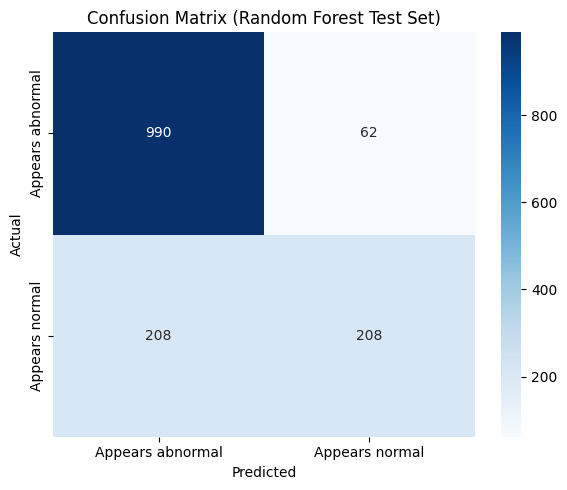

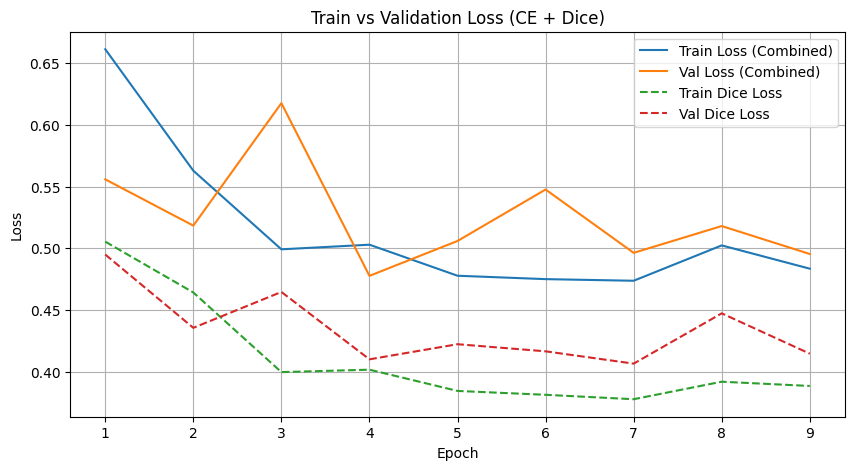

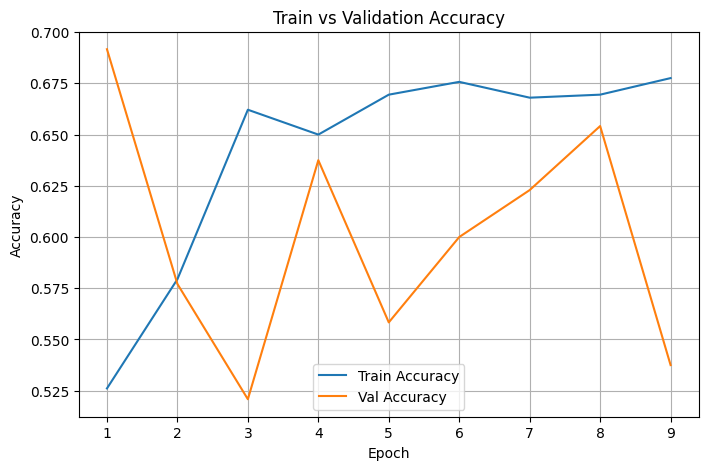


Summary:
Best AlexNet Val Accuracy: 0.6917
Random Forest Val Accuracy: 0.7063
Final Random Forest Test Accuracy: 0.8161
Final Test Precision: 0.8105, Recall: 0.8161, F1: 0.8025


In [9]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, WeightedRandomSampler, random_split
from torchvision import datasets, transforms
from tqdm import tqdm
import numpy as np
import os
import matplotlib.pyplot as plt

from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)
from sklearn.ensemble import RandomForestClassifier
import seaborn as sns


# Device configuration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


# Paths to train and test datasets
train_dir = '/kaggle/working/PCOSGen-train/train'
test_dir = '/kaggle/working/PCOSGen-train/test'


# Image transformations
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(20),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])


# Datasets
train_dataset = datasets.ImageFolder(train_dir, transform=train_transform)
test_dataset = datasets.ImageFolder(test_dir, transform=test_transform)


# Split train_dataset into train_subset + val_subset (85/15)
val_size = int(0.15 * len(train_dataset))
train_size = len(train_dataset) - val_size
train_subset, val_subset = random_split(
    train_dataset, [train_size, val_size]
)


# Count the number of samples per class (within train_subset)
train_targets = [train_dataset.targets[i] for i in train_subset.indices]
class_counts = np.bincount(train_targets)
class_weights = 1. / class_counts
sample_weights = [class_weights[label] for label in train_targets]

sampler = WeightedRandomSampler(
    weights=sample_weights,
    num_samples=len(train_subset),
    replacement=True
)

train_loader = DataLoader(
    train_subset,
    batch_size=64,
    sampler=sampler
)

val_loader = DataLoader(
    val_subset,
    batch_size=64,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)

num_classes = len(train_dataset.classes)


# ============================================================
# AlexNet architecture (224x224 input)
# ============================================================
class AlexNet(nn.Module):
    def __init__(self, num_classes):
        super(AlexNet, self).__init__()

        self.conv1 = nn.Conv2d(3, 96, kernel_size=11, stride=4)
        self.conv2 = nn.Conv2d(96, 256, kernel_size=5, padding=2)
        self.conv3 = nn.Conv2d(256, 384, kernel_size=3, padding=1)
        self.conv4 = nn.Conv2d(384, 384, kernel_size=3, padding=1)
        self.conv5 = nn.Conv2d(384, 256, kernel_size=3, padding=1)

        self.maxpool = nn.MaxPool2d(kernel_size=3, stride=2)
        self.dropout = nn.Dropout(0.5)

        self._to_linear = None
        self.convs(torch.randn(1, 3, 224, 224))

        self.fc1 = nn.Linear(self._to_linear, 4096)
        self.fc2 = nn.Linear(4096, 4096)
        self.fc3 = nn.Linear(4096, num_classes)

    def convs(self, x):
        x = F.relu(self.conv1(x))
        x = self.maxpool(x)

        x = F.relu(self.conv2(x))
        x = self.maxpool(x)

        x = F.relu(self.conv3(x))
        x = F.relu(self.conv4(x))
        x = F.relu(self.conv5(x))

        x = self.maxpool(x)

        if self._to_linear is None:
            self._to_linear = x.view(x.size(0), -1).shape[1]

        return x

    def forward(self, x):
        x = self.convs(x)
        x = x.view(x.size(0), -1)

        x = F.relu(self.fc1(x))
        x = self.dropout(x)

        x = F.relu(self.fc2(x))
        x = self.dropout(x)

        x = self.fc3(x)

        return x

    # NEW: extract FC2 features for Random Forest
    def extract_features(self, x):
        x = self.convs(x)
        x = x.view(x.size(0), -1)

        x = F.relu(self.fc1(x))
        x = self.dropout(x)

        x = F.relu(self.fc2(x))

        return x


alexnet = AlexNet(num_classes).to(device)


# ============================================================
# Dice Loss
# ============================================================
class DiceLoss(nn.Module):
    def __init__(self, num_classes, smooth=1e-6):
        super().__init__()
        self.num_classes = num_classes
        self.smooth = smooth

    def forward(self, logits, targets):
        probs = F.softmax(logits, dim=1)

        targets_one_hot = F.one_hot(
            targets,
            num_classes=self.num_classes
        ).float()

        intersection = (probs * targets_one_hot).sum(dim=0)

        union = (
            probs.sum(dim=0) +
            targets_one_hot.sum(dim=0)
        )

        dice_score = (
            (2. * intersection + self.smooth) /
            (union + self.smooth)
        )

        dice_loss = 1. - dice_score.mean()

        return dice_loss


# Combined CrossEntropy + Dice Loss
class CombinedLoss(nn.Module):
    def __init__(
        self,
        num_classes,
        ce_weight=0.5,
        dice_weight=0.5
    ):
        super().__init__()

        self.ce_loss = nn.CrossEntropyLoss()
        self.dice_loss = DiceLoss(num_classes)

        self.ce_weight = ce_weight
        self.dice_weight = dice_weight

    def forward(self, logits, targets):
        ce = self.ce_loss(logits, targets)
        dice = self.dice_loss(logits, targets)

        total = (
            self.ce_weight * ce +
            self.dice_weight * dice
        )

        return total, ce, dice


criterion = CombinedLoss(
    num_classes=num_classes,
    ce_weight=0.5,
    dice_weight=0.5
)

optimizer = optim.Adam(
    alexnet.parameters(),
    lr=0.001
)


# ============================================================
# Evaluation function
# ============================================================
def evaluate_model(model, loader):

    model.eval()

    correct = 0
    total = 0

    running_loss = 0.0
    running_ce = 0.0
    running_dice = 0.0

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss, ce, dice = criterion(
                outputs,
                labels
            )

            running_loss += loss.item()
            running_ce += ce.item()
            running_dice += dice.item()

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)

            correct += (
                predicted == labels
            ).sum().item()

    accuracy = correct / total

    n = len(loader)

    return (
        accuracy,
        running_loss / n,
        running_ce / n,
        running_dice / n
    )


def get_predictions(model, loader):

    model.eval()

    all_preds = []
    all_labels = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            _, predicted = torch.max(outputs, 1)

            all_preds.extend(
                predicted.cpu().numpy()
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

    return all_labels, all_preds


# ============================================================
# Early stopping setup
# ============================================================
best_accuracy = 0.0

best_model_path = "AlexNet_best.pkl"

patience = 8

epochs_no_improve = 0

max_epochs = 50


train_losses, train_accs = [], []
val_losses, val_accs = [], []

train_ce_losses, train_dice_losses = [], []
val_ce_losses, val_dice_losses = [], []


# ============================================================
# Train AlexNet feature extractor
# ============================================================
for epoch in range(max_epochs):

    alexnet.train()

    running_loss = 0.0
    running_ce = 0.0
    running_dice = 0.0

    correct_train = 0
    total_train = 0

    for images, labels in tqdm(train_loader):

        images = images.to(device)
        labels = labels.to(device)

        outputs = alexnet(images)

        loss, ce, dice = criterion(
            outputs,
            labels
        )

        optimizer.zero_grad()

        loss.backward()

        optimizer.step()

        running_loss += loss.item()
        running_ce += ce.item()
        running_dice += dice.item()

        _, predicted = torch.max(outputs, 1)

        total_train += labels.size(0)

        correct_train += (
            predicted == labels
        ).sum().item()

    train_accuracy = correct_train / total_train

    n_batches = len(train_loader)

    train_loss = running_loss / n_batches
    train_ce = running_ce / n_batches
    train_dice = running_dice / n_batches

    val_accuracy, val_loss, val_ce, val_dice = evaluate_model(
        alexnet,
        val_loader
    )

    train_losses.append(train_loss)
    train_accs.append(train_accuracy)

    val_losses.append(val_loss)
    val_accs.append(val_accuracy)

    train_ce_losses.append(train_ce)
    train_dice_losses.append(train_dice)

    val_ce_losses.append(val_ce)
    val_dice_losses.append(val_dice)

    print(
        f'Epoch [{epoch+1}/{max_epochs}] '
        f'Train Loss: {train_loss:.4f} '
        f'(CE: {train_ce:.4f}, Dice: {train_dice:.4f}), '
        f'Train Acc: {train_accuracy:.4f} | '
        f'Val Loss: {val_loss:.4f} '
        f'(CE: {val_ce:.4f}, Dice: {val_dice:.4f}), '
        f'Val Acc: {val_accuracy:.4f}'
    )

    # Early stopping logic
    if val_accuracy > best_accuracy:

        best_accuracy = val_accuracy

        epochs_no_improve = 0

        print(
            f'  -> Saving best model '
            f'(Val Accuracy: {best_accuracy:.4f})'
        )

        torch.save(
            alexnet.state_dict(),
            best_model_path
        )

    else:

        epochs_no_improve += 1

        print(
            f'  -> No improvement for '
            f'{epochs_no_improve}/{patience} epochs'
        )

    if epochs_no_improve >= patience:

        print(
            f'\nEarly stopping triggered at epoch '
            f'{epoch+1}. '
            f'Best Val Accuracy: {best_accuracy:.4f}'
        )

        break


# ============================================================
# Load best AlexNet
# ============================================================
best_alexnet_model = AlexNet(num_classes).to(device)

best_alexnet_model.load_state_dict(
    torch.load(
        best_model_path,
        map_location=device
    )
)


# ============================================================
# RANDOM FOREST
# ============================================================
print("\n" + "=" * 60)
print("Training Random Forest on AlexNet features")
print("=" * 60)


# Loader for extracting training features
feature_train_loader = DataLoader(
    train_subset,
    batch_size=64,
    shuffle=False
)


def extract_features(model, loader):

    model.eval()

    features = []
    labels_list = []

    with torch.no_grad():

        for images, labels in tqdm(loader):

            images = images.to(device)

            outputs = model.extract_features(images)

            features.append(
                outputs.cpu().numpy()
            )

            labels_list.append(
                labels.numpy()
            )

    features = np.concatenate(
        features,
        axis=0
    )

    labels_list = np.concatenate(
        labels_list,
        axis=0
    )

    return features, labels_list


# Extract features
X_train, y_train = extract_features(
    best_alexnet_model,
    feature_train_loader
)

X_val, y_val = extract_features(
    best_alexnet_model,
    val_loader
)

X_test, y_test = extract_features(
    best_alexnet_model,
    test_loader
)


print("Training features shape:", X_train.shape)
print("Validation features shape:", X_val.shape)
print("Test features shape:", X_test.shape)


# Random Forest classifier
random_forest = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)


# Train Random Forest
random_forest.fit(
    X_train,
    y_train
)


# ============================================================
# Random Forest Validation
# ============================================================
rf_val_preds = random_forest.predict(X_val)

rf_val_accuracy = (
    rf_val_preds == y_val
).mean()

print(
    f"\nRandom Forest Validation Accuracy: "
    f"{rf_val_accuracy:.4f}"
)


# ============================================================
# Random Forest TEST
# ============================================================
rf_test_preds = random_forest.predict(X_test)

test_accuracy = (
    rf_test_preds == y_test
).mean()


print(
    f'\nFinal Random Forest Test Accuracy: '
    f'{test_accuracy:.4f}'
)


# ============================================================
# Precision, Recall, F1
# ============================================================
precision = precision_score(
    y_test,
    rf_test_preds,
    average='weighted'
)

recall = recall_score(
    y_test,
    rf_test_preds,
    average='weighted'
)

f1 = f1_score(
    y_test,
    rf_test_preds,
    average='weighted'
)


print(
    f'\nTest Precision (weighted): {precision:.4f}'
)

print(
    f'Test Recall (weighted):    {recall:.4f}'
)

print(
    f'Test F1-score (weighted):  {f1:.4f}'
)


# ============================================================
# Per-class report
# ============================================================
class_names = train_dataset.classes

print('\nPer-class report:')

print(
    classification_report(
        y_test,
        rf_test_preds,
        target_names=class_names
    )
)


# ============================================================
# Confusion Matrix
# ============================================================
cm = confusion_matrix(
    y_test,
    rf_test_preds
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.title(
    'Confusion Matrix (Random Forest Test Set)'
)

plt.tight_layout()

plt.show()


# ============================================================
# Plot Train vs Val Loss
# ============================================================
epochs_range = range(
    1,
    len(train_losses) + 1
)

plt.figure(figsize=(10, 5))

plt.plot(
    epochs_range,
    train_losses,
    label='Train Loss (Combined)'
)

plt.plot(
    epochs_range,
    val_losses,
    label='Val Loss (Combined)'
)

plt.plot(
    epochs_range,
    train_dice_losses,
    '--',
    label='Train Dice Loss'
)

plt.plot(
    epochs_range,
    val_dice_losses,
    '--',
    label='Val Dice Loss'
)

plt.xlabel('Epoch')
plt.ylabel('Loss')

plt.title(
    'Train vs Validation Loss (CE + Dice)'
)

plt.legend()
plt.grid(True)

plt.show()


# ============================================================
# Plot Train vs Val Accuracy
# ============================================================
plt.figure(figsize=(8, 5))

plt.plot(
    epochs_range,
    train_accs,
    label='Train Accuracy'
)

plt.plot(
    epochs_range,
    val_accs,
    label='Val Accuracy'
)

plt.xlabel('Epoch')
plt.ylabel('Accuracy')

plt.title(
    'Train vs Validation Accuracy'
)

plt.legend()
plt.grid(True)

plt.show()


# ============================================================
# Summary
# ============================================================
print('\nSummary:')

print(
    f'Best AlexNet Val Accuracy: '
    f'{best_accuracy:.4f}'
)

print(
    f'Random Forest Val Accuracy: '
    f'{rf_val_accuracy:.4f}'
)

print(
    f'Final Random Forest Test Accuracy: '
    f'{test_accuracy:.4f}'
)

print(
    f'Final Test Precision: '
    f'{precision:.4f}, '
    f'Recall: {recall:.4f}, '
    f'F1: {f1:.4f}'
)

# KNN

100%|██████████| 43/43 [00:11<00:00,  3.63it/s]


Epoch [1/50] Train Loss: 0.6301 (CE: 0.7536, Dice: 0.5065), Train Acc: 0.4993 | Val Loss: 0.6023 (CE: 0.6766, Dice: 0.5281), Val Acc: 0.7479
  -> Saving best model (Val Accuracy: 0.7479)


100%|██████████| 43/43 [00:11<00:00,  3.75it/s]


Epoch [2/50] Train Loss: 0.5956 (CE: 0.6918, Dice: 0.4994), Train Acc: 0.5140 | Val Loss: 0.6106 (CE: 0.6894, Dice: 0.5317), Val Acc: 0.4542
  -> No improvement for 1/8 epochs


100%|██████████| 43/43 [00:11<00:00,  3.81it/s]


...

Epoch [8/50] Train Loss: 0.4914 (CE: 0.5909, Dice: 0.3919), Train Acc: 0.6732 | Val Loss: 0.5321 (CE: 0.6278, Dice: 0.4363), Val Acc: 0.5625
  -> No improvement for 7/8 epochs


100%|██████████| 43/43 [00:11<00:00,  3.81it/s]


Epoch [9/50] Train Loss: 0.5126 (CE: 0.6128, Dice: 0.4125), Train Acc: 0.6471 | Val Loss: 0.5121 (CE: 0.5824, Dice: 0.4418), Val Acc: 0.5667
  -> No improvement for 8/8 epochs

Early stopping triggered at epoch 9. Best Val Accuracy: 0.7479

Training KNN on AlexNet features


100%|██████████| 23/23 [00:04<00:00,  4.94it/s]


Training features shape: (2720, 4096)
Validation features shape: (480, 4096)
Test features shape: (1468, 4096)

KNN Validation Accuracy: 0.6979

Final KNN Test Accuracy: 0.8025

Test Precision (weighted): 0.7979
Test Recall (weighted):    0.8025
Test F1-score (weighted):  0.7823

Per-class report:
                  precision    recall  f1-score   support

Appears abnormal       0.81      0.95      0.87      1052
  Appears normal       0.77      0.43      0.55       416

        accuracy                           0.80      1468
       macro avg       0.79      0.69      0.71      1468
    weighted avg       0.80      0.80      0.78      1468



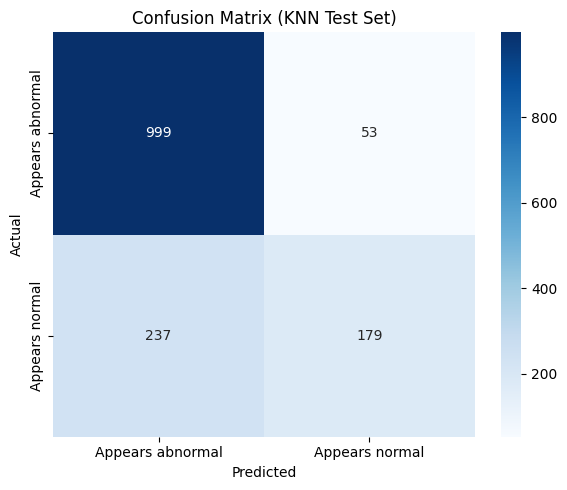

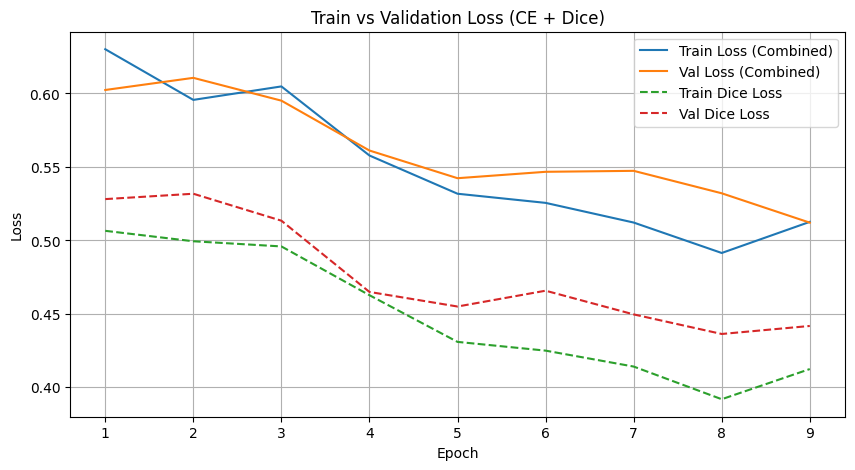

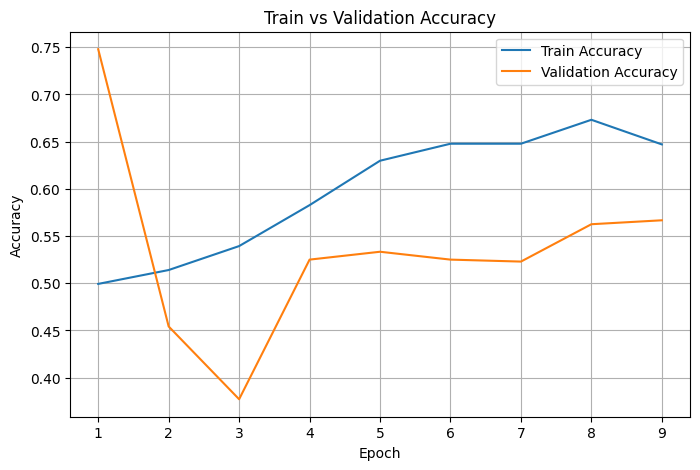


Summary:
Best AlexNet Val Accuracy: 0.7479
KNN Val Accuracy: 0.6979
Final KNN Test Accuracy: 0.8025
Final Test Precision: 0.7979, Recall: 0.8025, F1: 0.7823


In [11]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, WeightedRandomSampler, random_split
from torchvision import datasets, transforms
from tqdm import tqdm
import numpy as np
import os
import matplotlib.pyplot as plt

from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)
from sklearn.neighbors import KNeighborsClassifier
import seaborn as sns


# Device configuration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


# Paths to train and test datasets
train_dir = '/kaggle/working/PCOSGen-train/train'
test_dir = '/kaggle/working/PCOSGen-train/test'


# Image transformations
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(20),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])


# Datasets
train_dataset = datasets.ImageFolder(train_dir, transform=train_transform)
test_dataset = datasets.ImageFolder(test_dir, transform=test_transform)


# Split train_dataset into train_subset + val_subset (85/15)
val_size = int(0.15 * len(train_dataset))
train_size = len(train_dataset) - val_size
train_subset, val_subset = random_split(
    train_dataset, [train_size, val_size]
)


# Count the number of samples per class (within train_subset)
train_targets = [train_dataset.targets[i] for i in train_subset.indices]
class_counts = np.bincount(train_targets)
class_weights = 1. / class_counts
sample_weights = [class_weights[label] for label in train_targets]

sampler = WeightedRandomSampler(
    weights=sample_weights,
    num_samples=len(train_subset),
    replacement=True
)

train_loader = DataLoader(
    train_subset,
    batch_size=64,
    sampler=sampler
)

val_loader = DataLoader(
    val_subset,
    batch_size=64,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)

num_classes = len(train_dataset.classes)


# ============================================================
# AlexNet architecture (224x224 input)
# ============================================================
class AlexNet(nn.Module):
    def __init__(self, num_classes):
        super(AlexNet, self).__init__()

        self.conv1 = nn.Conv2d(3, 96, kernel_size=11, stride=4)
        self.conv2 = nn.Conv2d(96, 256, kernel_size=5, padding=2)
        self.conv3 = nn.Conv2d(256, 384, kernel_size=3, padding=1)
        self.conv4 = nn.Conv2d(384, 384, kernel_size=3, padding=1)
        self.conv5 = nn.Conv2d(384, 256, kernel_size=3, padding=1)

        self.maxpool = nn.MaxPool2d(kernel_size=3, stride=2)
        self.dropout = nn.Dropout(0.5)

        self._to_linear = None
        self.convs(torch.randn(1, 3, 224, 224))

        self.fc1 = nn.Linear(self._to_linear, 4096)
        self.fc2 = nn.Linear(4096, 4096)
        self.fc3 = nn.Linear(4096, num_classes)

    def convs(self, x):
        x = F.relu(self.conv1(x))
        x = self.maxpool(x)

        x = F.relu(self.conv2(x))
        x = self.maxpool(x)

        x = F.relu(self.conv3(x))
        x = F.relu(self.conv4(x))
        x = F.relu(self.conv5(x))

        x = self.maxpool(x)

        if self._to_linear is None:
            self._to_linear = x.view(x.size(0), -1).shape[1]

        return x

    def forward(self, x):
        x = self.convs(x)
        x = x.view(x.size(0), -1)

        x = F.relu(self.fc1(x))
        x = self.dropout(x)

        x = F.relu(self.fc2(x))
        x = self.dropout(x)

        x = self.fc3(x)

        return x

    # Extract features for KNN
    def extract_features(self, x):
        x = self.convs(x)
        x = x.view(x.size(0), -1)

        x = F.relu(self.fc1(x))
        x = self.dropout(x)

        x = F.relu(self.fc2(x))

        return x


alexnet = AlexNet(num_classes).to(device)


# ============================================================
# Dice Loss
# ============================================================
class DiceLoss(nn.Module):
    def __init__(self, num_classes, smooth=1e-6):
        super().__init__()
        self.num_classes = num_classes
        self.smooth = smooth

    def forward(self, logits, targets):
        probs = F.softmax(logits, dim=1)

        targets_one_hot = F.one_hot(
            targets,
            num_classes=self.num_classes
        ).float()

        intersection = (probs * targets_one_hot).sum(dim=0)

        union = (
            probs.sum(dim=0) +
            targets_one_hot.sum(dim=0)
        )

        dice_score = (
            (2. * intersection + self.smooth) /
            (union + self.smooth)
        )

        dice_loss = 1. - dice_score.mean()

        return dice_loss


# Combined CrossEntropy + Dice Loss
class CombinedLoss(nn.Module):
    def __init__(
        self,
        num_classes,
        ce_weight=0.5,
        dice_weight=0.5
    ):
        super().__init__()

        self.ce_loss = nn.CrossEntropyLoss()
        self.dice_loss = DiceLoss(num_classes)

        self.ce_weight = ce_weight
        self.dice_weight = dice_weight

    def forward(self, logits, targets):
        ce = self.ce_loss(logits, targets)
        dice = self.dice_loss(logits, targets)

        total = (
            self.ce_weight * ce +
            self.dice_weight * dice
        )

        return total, ce, dice


criterion = CombinedLoss(
    num_classes=num_classes,
    ce_weight=0.5,
    dice_weight=0.5
)

optimizer = optim.Adam(
    alexnet.parameters(),
    lr=0.001
)


# ============================================================
# Evaluation function
# ============================================================
def evaluate_model(model, loader):

    model.eval()

    correct = 0
    total = 0

    running_loss = 0.0
    running_ce = 0.0
    running_dice = 0.0

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss, ce, dice = criterion(
                outputs,
                labels
            )

            running_loss += loss.item()
            running_ce += ce.item()
            running_dice += dice.item()

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)

            correct += (
                predicted == labels
            ).sum().item()

    accuracy = correct / total

    n = len(loader)

    return (
        accuracy,
        running_loss / n,
        running_ce / n,
        running_dice / n
    )


def get_predictions(model, loader):

    model.eval()

    all_preds = []
    all_labels = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            _, predicted = torch.max(outputs, 1)

            all_preds.extend(
                predicted.cpu().numpy()
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

    return all_labels, all_preds


# ============================================================
# Early stopping setup
# ============================================================
best_accuracy = 0.0

best_model_path = "AlexNet_best.pkl"

patience = 8

epochs_no_improve = 0

max_epochs = 50


train_losses, train_accs = [], []
val_losses, val_accs = [], []

train_ce_losses, train_dice_losses = [], []
val_ce_losses, val_dice_losses = [], []


# ============================================================
# Train AlexNet feature extractor
# ============================================================
for epoch in range(max_epochs):

    alexnet.train()

    running_loss = 0.0
    running_ce = 0.0
    running_dice = 0.0

    correct_train = 0
    total_train = 0

    for images, labels in tqdm(train_loader):

        images = images.to(device)
        labels = labels.to(device)

        outputs = alexnet(images)

        loss, ce, dice = criterion(
            outputs,
            labels
        )

        optimizer.zero_grad()

        loss.backward()

        optimizer.step()

        running_loss += loss.item()
        running_ce += ce.item()
        running_dice += dice.item()

        _, predicted = torch.max(outputs, 1)

        total_train += labels.size(0)

        correct_train += (
            predicted == labels
        ).sum().item()

    train_accuracy = correct_train / total_train

    n_batches = len(train_loader)

    train_loss = running_loss / n_batches
    train_ce = running_ce / n_batches
    train_dice = running_dice / n_batches

    val_accuracy, val_loss, val_ce, val_dice = evaluate_model(
        alexnet,
        val_loader
    )

    train_losses.append(train_loss)
    train_accs.append(train_accuracy)

    val_losses.append(val_loss)
    val_accs.append(val_accuracy)

    train_ce_losses.append(train_ce)
    train_dice_losses.append(train_dice)

    val_ce_losses.append(val_ce)
    val_dice_losses.append(val_dice)

    print(
        f'Epoch [{epoch+1}/{max_epochs}] '
        f'Train Loss: {train_loss:.4f} '
        f'(CE: {train_ce:.4f}, Dice: {train_dice:.4f}), '
        f'Train Acc: {train_accuracy:.4f} | '
        f'Val Loss: {val_loss:.4f} '
        f'(CE: {val_ce:.4f}, Dice: {val_dice:.4f}), '
        f'Val Acc: {val_accuracy:.4f}'
    )

    # Early stopping logic
    if val_accuracy > best_accuracy:

        best_accuracy = val_accuracy

        epochs_no_improve = 0

        print(
            f'  -> Saving best model '
            f'(Val Accuracy: {best_accuracy:.4f})'
        )

        torch.save(
            alexnet.state_dict(),
            best_model_path
        )

    else:

        epochs_no_improve += 1

        print(
            f'  -> No improvement for '
            f'{epochs_no_improve}/{patience} epochs'
        )

    if epochs_no_improve >= patience:

        print(
            f'\nEarly stopping triggered at epoch '
            f'{epoch+1}. '
            f'Best Val Accuracy: {best_accuracy:.4f}'
        )

        break


# ============================================================
# Load best AlexNet
# ============================================================
best_alexnet_model = AlexNet(num_classes).to(device)

best_alexnet_model.load_state_dict(
    torch.load(
        best_model_path,
        map_location=device
    )
)


# ============================================================
# KNN
# ============================================================
print("\n" + "=" * 60)
print("Training KNN on AlexNet features")
print("=" * 60)


# Loader for extracting training features
feature_train_loader = DataLoader(
    train_subset,
    batch_size=64,
    shuffle=False
)


def extract_features(model, loader):

    model.eval()

    features = []
    labels_list = []

    with torch.no_grad():

        for images, labels in tqdm(loader):

            images = images.to(device)

            outputs = model.extract_features(images)

            features.append(
                outputs.cpu().numpy()
            )

            labels_list.append(
                labels.numpy()
            )

    features = np.concatenate(
        features,
        axis=0
    )

    labels_list = np.concatenate(
        labels_list,
        axis=0
    )

    return features, labels_list


# Extract AlexNet features
X_train, y_train = extract_features(
    best_alexnet_model,
    feature_train_loader
)

X_val, y_val = extract_features(
    best_alexnet_model,
    val_loader
)

X_test, y_test = extract_features(
    best_alexnet_model,
    test_loader
)


print("Training features shape:", X_train.shape)
print("Validation features shape:", X_val.shape)
print("Test features shape:", X_test.shape)


# ============================================================
# KNN classifier
# ============================================================
knn = KNeighborsClassifier(
    n_neighbors=5,
    n_jobs=-1
)


# Train KNN
knn.fit(
    X_train,
    y_train
)


# ============================================================
# KNN Validation
# ============================================================
knn_val_preds = knn.predict(X_val)

knn_val_accuracy = (
    knn_val_preds == y_val
).mean()

print(
    f"\nKNN Validation Accuracy: "
    f"{knn_val_accuracy:.4f}"
)


# ============================================================
# KNN TEST
# ============================================================
knn_test_preds = knn.predict(X_test)

test_accuracy = (
    knn_test_preds == y_test
).mean()


print(
    f'\nFinal KNN Test Accuracy: '
    f'{test_accuracy:.4f}'
)


# ============================================================
# Precision, Recall, F1
# ============================================================
precision = precision_score(
    y_test,
    knn_test_preds,
    average='weighted'
)

recall = recall_score(
    y_test,
    knn_test_preds,
    average='weighted'
)

f1 = f1_score(
    y_test,
    knn_test_preds,
    average='weighted'
)


print(
    f'\nTest Precision (weighted): {precision:.4f}'
)

print(
    f'Test Recall (weighted):    {recall:.4f}'
)

print(
    f'Test F1-score (weighted):  {f1:.4f}'
)


# ============================================================
# Per-class report
# ============================================================
class_names = train_dataset.classes

print('\nPer-class report:')

print(
    classification_report(
        y_test,
        knn_test_preds,
        target_names=class_names
    )
)


# ============================================================
# Confusion Matrix
# ============================================================
cm = confusion_matrix(
    y_test,
    knn_test_preds
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.title(
    'Confusion Matrix (KNN Test Set)'
)

plt.tight_layout()

plt.show()


# ============================================================
# Plot Train vs Val Loss
# ============================================================
epochs_range = range(
    1,
    len(train_losses) + 1
)

plt.figure(figsize=(10, 5))

plt.plot(
    epochs_range,
    train_losses,
    label='Train Loss (Combined)'
)

plt.plot(
    epochs_range,
    val_losses,
    label='Val Loss (Combined)'
)

plt.plot(
    epochs_range,
    train_dice_losses,
    '--',
    label='Train Dice Loss'
)

plt.plot(
    epochs_range,
    val_dice_losses,
    '--',
    label='Val Dice Loss'
)

plt.xlabel('Epoch')
plt.ylabel('Loss')

plt.title(
    'Train vs Validation Loss (CE + Dice)'
)

plt.legend()
plt.grid(True)

plt.show()


# ============================================================
# Plot Train vs Val Accuracy
# ============================================================
plt.figure(figsize=(8, 5))

plt.plot(
    epochs_range,
    train_accs,
    label='Train Accuracy'
)

plt.plot(
    epochs_range,
    val_accs,
    label='Validation Accuracy'
)

plt.xlabel('Epoch')
plt.ylabel('Accuracy')

plt.title(
    'Train vs Validation Accuracy'
)

plt.legend()
plt.grid(True)

plt.show()


# ============================================================
# Summary
# ============================================================
print('\nSummary:')

print(
    f'Best AlexNet Val Accuracy: '
    f'{best_accuracy:.4f}'
)

print(
    f'KNN Val Accuracy: '
    f'{knn_val_accuracy:.4f}'
)

print(
    f'Final KNN Test Accuracy: '
    f'{test_accuracy:.4f}'
)

print(
    f'Final Test Precision: '
    f'{precision:.4f}, '
    f'Recall: {recall:.4f}, '
    f'F1: {f1:.4f}'
)

# Naive Bayes

100%|██████████| 43/43 [00:11<00:00,  3.69it/s]


Epoch [1/50] Train Loss: 0.6157 (CE: 0.7260, Dice: 0.5055), Train Acc: 0.5022 | Val Loss: 0.5842 (CE: 0.6570, Dice: 0.5114), Val Acc: 0.6438
  -> Saving best model (Val Accuracy: 0.6438)


100%|██████████| 43/43 [00:11<00:00,  3.68it/s]


Epoch [2/50] Train Loss: 0.5831 (CE: 0.6863, Dice: 0.4798), Train Acc: 0.6015 | Val Loss: 0.5877 (CE: 0.6829, Dice: 0.4925), Val Acc: 0.5979
  -> No improvement for 1/8 epochs


100%|██████████| 43/43 [00:11<00:00,  3.71it/s]


...

Epoch [12/50] Train Loss: 0.4607 (CE: 0.5526, Dice: 0.3688), Train Acc: 0.6779 | Val Loss: 0.5333 (CE: 0.6417, Dice: 0.4249), Val Acc: 0.5813
  -> No improvement for 7/8 epochs


100%|██████████| 43/43 [00:11<00:00,  3.68it/s]


Epoch [13/50] Train Loss: 0.4412 (CE: 0.5265, Dice: 0.3559), Train Acc: 0.6971 | Val Loss: 0.5103 (CE: 0.6262, Dice: 0.3944), Val Acc: 0.6312
  -> No improvement for 8/8 epochs

Early stopping triggered at epoch 13. Best Val Accuracy: 0.6937

Training Naive Bayes on AlexNet features


100%|██████████| 23/23 [00:04<00:00,  4.95it/s]


Training features shape: (2720, 4096)
Validation features shape: (480, 4096)
Test features shape: (1468, 4096)

Naive Bayes Validation Accuracy: 0.4875

Final Naive Bayes Test Accuracy: 0.7507

Test Precision (weighted): 0.8351
Test Recall (weighted):    0.7507
Test F1-score (weighted):  0.7630

Per-class report:
                  precision    recall  f1-score   support

Appears abnormal       0.95      0.69      0.80      1052
  Appears normal       0.54      0.92      0.68       416

        accuracy                           0.75      1468
       macro avg       0.74      0.80      0.74      1468
    weighted avg       0.84      0.75      0.76      1468



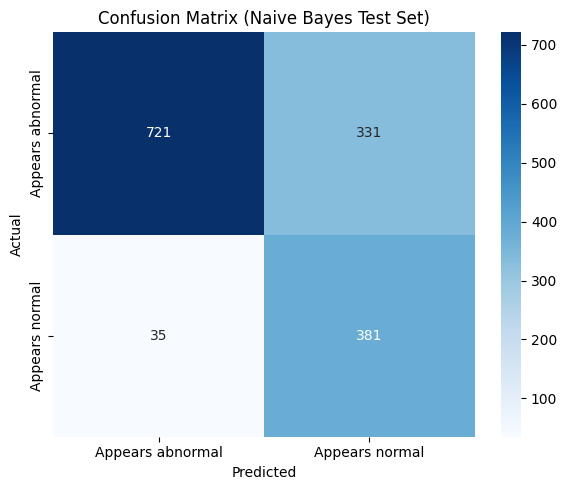

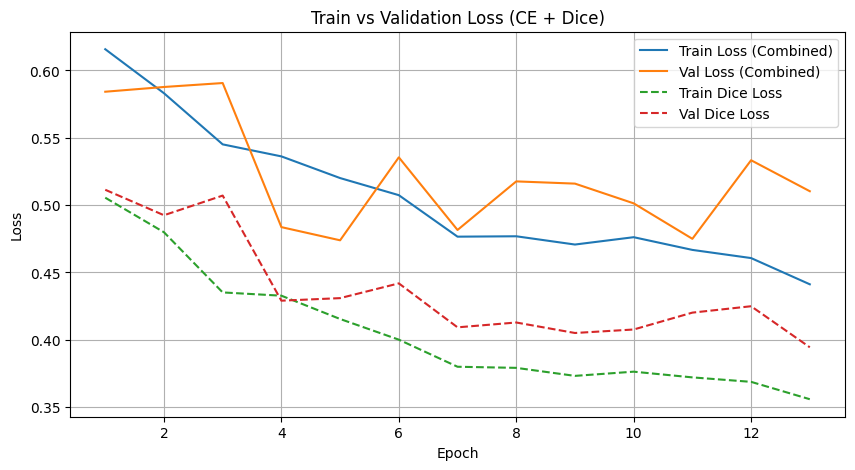

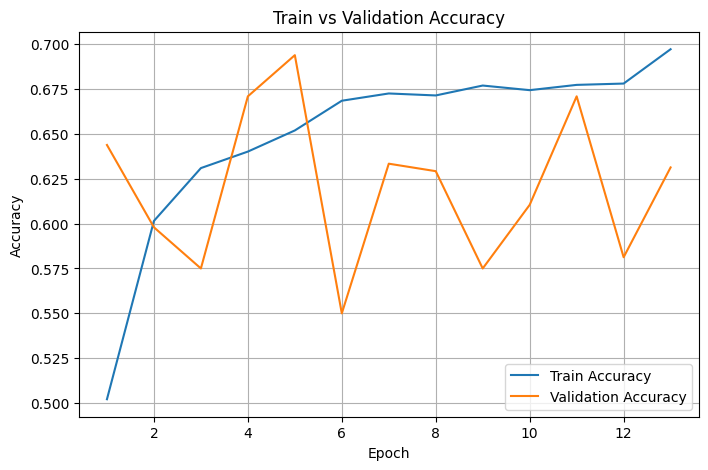


Summary:
Best AlexNet Val Accuracy: 0.6937
Naive Bayes Val Accuracy: 0.4875
Final Naive Bayes Test Accuracy: 0.7507
Final Test Precision: 0.8351, Recall: 0.7507, F1: 0.7630


In [13]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, WeightedRandomSampler, random_split
from torchvision import datasets, transforms
from tqdm import tqdm
import numpy as np
import os
import matplotlib.pyplot as plt

from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)
from sklearn.naive_bayes import GaussianNB
import seaborn as sns


# Device configuration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


# Paths to train and test datasets
train_dir = '/kaggle/working/PCOSGen-train/train'
test_dir = '/kaggle/working/PCOSGen-train/test'


# Image transformations
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(20),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])


# Datasets
train_dataset = datasets.ImageFolder(train_dir, transform=train_transform)
test_dataset = datasets.ImageFolder(test_dir, transform=test_transform)


# Split train_dataset into train_subset + val_subset (85/15)
val_size = int(0.15 * len(train_dataset))
train_size = len(train_dataset) - val_size
train_subset, val_subset = random_split(
    train_dataset, [train_size, val_size]
)


# Count the number of samples per class (within train_subset)
train_targets = [train_dataset.targets[i] for i in train_subset.indices]
class_counts = np.bincount(train_targets)
class_weights = 1. / class_counts
sample_weights = [class_weights[label] for label in train_targets]

sampler = WeightedRandomSampler(
    weights=sample_weights,
    num_samples=len(train_subset),
    replacement=True
)

train_loader = DataLoader(
    train_subset,
    batch_size=64,
    sampler=sampler
)

val_loader = DataLoader(
    val_subset,
    batch_size=64,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)

num_classes = len(train_dataset.classes)


# ============================================================
# AlexNet architecture (224x224 input)
# ============================================================
class AlexNet(nn.Module):
    def __init__(self, num_classes):
        super(AlexNet, self).__init__()

        self.conv1 = nn.Conv2d(3, 96, kernel_size=11, stride=4)
        self.conv2 = nn.Conv2d(96, 256, kernel_size=5, padding=2)
        self.conv3 = nn.Conv2d(256, 384, kernel_size=3, padding=1)
        self.conv4 = nn.Conv2d(384, 384, kernel_size=3, padding=1)
        self.conv5 = nn.Conv2d(384, 256, kernel_size=3, padding=1)

        self.maxpool = nn.MaxPool2d(kernel_size=3, stride=2)
        self.dropout = nn.Dropout(0.5)

        self._to_linear = None
        self.convs(torch.randn(1, 3, 224, 224))

        self.fc1 = nn.Linear(self._to_linear, 4096)
        self.fc2 = nn.Linear(4096, 4096)
        self.fc3 = nn.Linear(4096, num_classes)

    def convs(self, x):
        x = F.relu(self.conv1(x))
        x = self.maxpool(x)

        x = F.relu(self.conv2(x))
        x = self.maxpool(x)

        x = F.relu(self.conv3(x))
        x = F.relu(self.conv4(x))
        x = F.relu(self.conv5(x))

        x = self.maxpool(x)

        if self._to_linear is None:
            self._to_linear = x.view(x.size(0), -1).shape[1]

        return x

    def forward(self, x):
        x = self.convs(x)
        x = x.view(x.size(0), -1)

        x = F.relu(self.fc1(x))
        x = self.dropout(x)

        x = F.relu(self.fc2(x))
        x = self.dropout(x)

        x = self.fc3(x)

        return x

    # Extract features for Naive Bayes
    def extract_features(self, x):
        x = self.convs(x)
        x = x.view(x.size(0), -1)

        x = F.relu(self.fc1(x))
        x = self.dropout(x)

        x = F.relu(self.fc2(x))

        return x


alexnet = AlexNet(num_classes).to(device)


# ============================================================
# Dice Loss
# ============================================================
class DiceLoss(nn.Module):
    def __init__(self, num_classes, smooth=1e-6):
        super().__init__()
        self.num_classes = num_classes
        self.smooth = smooth

    def forward(self, logits, targets):
        probs = F.softmax(logits, dim=1)

        targets_one_hot = F.one_hot(
            targets,
            num_classes=self.num_classes
        ).float()

        intersection = (probs * targets_one_hot).sum(dim=0)

        union = (
            probs.sum(dim=0) +
            targets_one_hot.sum(dim=0)
        )

        dice_score = (
            (2. * intersection + self.smooth) /
            (union + self.smooth)
        )

        dice_loss = 1. - dice_score.mean()

        return dice_loss


# Combined CrossEntropy + Dice Loss
class CombinedLoss(nn.Module):
    def __init__(
        self,
        num_classes,
        ce_weight=0.5,
        dice_weight=0.5
    ):
        super().__init__()

        self.ce_loss = nn.CrossEntropyLoss()
        self.dice_loss = DiceLoss(num_classes)

        self.ce_weight = ce_weight
        self.dice_weight = dice_weight

    def forward(self, logits, targets):
        ce = self.ce_loss(logits, targets)
        dice = self.dice_loss(logits, targets)

        total = (
            self.ce_weight * ce +
            self.dice_weight * dice
        )

        return total, ce, dice


criterion = CombinedLoss(
    num_classes=num_classes,
    ce_weight=0.5,
    dice_weight=0.5
)

optimizer = optim.Adam(
    alexnet.parameters(),
    lr=0.001
)


# ============================================================
# Evaluation function
# ============================================================
def evaluate_model(model, loader):

    model.eval()

    correct = 0
    total = 0

    running_loss = 0.0
    running_ce = 0.0
    running_dice = 0.0

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss, ce, dice = criterion(
                outputs,
                labels
            )

            running_loss += loss.item()
            running_ce += ce.item()
            running_dice += dice.item()

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)

            correct += (
                predicted == labels
            ).sum().item()

    accuracy = correct / total

    n = len(loader)

    return (
        accuracy,
        running_loss / n,
        running_ce / n,
        running_dice / n
    )


def get_predictions(model, loader):

    model.eval()

    all_preds = []
    all_labels = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            _, predicted = torch.max(outputs, 1)

            all_preds.extend(
                predicted.cpu().numpy()
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

    return all_labels, all_preds


# ============================================================
# Early stopping setup
# ============================================================
best_accuracy = 0.0

best_model_path = "AlexNet_best.pkl"

patience = 8

epochs_no_improve = 0

max_epochs = 50


train_losses, train_accs = [], []
val_losses, val_accs = [], []

train_ce_losses, train_dice_losses = [], []
val_ce_losses, val_dice_losses = [], []


# ============================================================
# Train AlexNet feature extractor
# ============================================================
for epoch in range(max_epochs):

    alexnet.train()

    running_loss = 0.0
    running_ce = 0.0
    running_dice = 0.0

    correct_train = 0
    total_train = 0

    for images, labels in tqdm(train_loader):

        images = images.to(device)
        labels = labels.to(device)

        outputs = alexnet(images)

        loss, ce, dice = criterion(
            outputs,
            labels
        )

        optimizer.zero_grad()

        loss.backward()

        optimizer.step()

        running_loss += loss.item()
        running_ce += ce.item()
        running_dice += dice.item()

        _, predicted = torch.max(outputs, 1)

        total_train += labels.size(0)

        correct_train += (
            predicted == labels
        ).sum().item()

    train_accuracy = correct_train / total_train

    n_batches = len(train_loader)

    train_loss = running_loss / n_batches
    train_ce = running_ce / n_batches
    train_dice = running_dice / n_batches

    val_accuracy, val_loss, val_ce, val_dice = evaluate_model(
        alexnet,
        val_loader
    )

    train_losses.append(train_loss)
    train_accs.append(train_accuracy)

    val_losses.append(val_loss)
    val_accs.append(val_accuracy)

    train_ce_losses.append(train_ce)
    train_dice_losses.append(train_dice)

    val_ce_losses.append(val_ce)
    val_dice_losses.append(val_dice)

    print(
        f'Epoch [{epoch+1}/{max_epochs}] '
        f'Train Loss: {train_loss:.4f} '
        f'(CE: {train_ce:.4f}, Dice: {train_dice:.4f}), '
        f'Train Acc: {train_accuracy:.4f} | '
        f'Val Loss: {val_loss:.4f} '
        f'(CE: {val_ce:.4f}, Dice: {val_dice:.4f}), '
        f'Val Acc: {val_accuracy:.4f}'
    )

    # Early stopping logic
    if val_accuracy > best_accuracy:

        best_accuracy = val_accuracy

        epochs_no_improve = 0

        print(
            f'  -> Saving best model '
            f'(Val Accuracy: {best_accuracy:.4f})'
        )

        torch.save(
            alexnet.state_dict(),
            best_model_path
        )

    else:

        epochs_no_improve += 1

        print(
            f'  -> No improvement for '
            f'{epochs_no_improve}/{patience} epochs'
        )

    if epochs_no_improve >= patience:

        print(
            f'\nEarly stopping triggered at epoch '
            f'{epoch+1}. '
            f'Best Val Accuracy: {best_accuracy:.4f}'
        )

        break


# ============================================================
# Load best AlexNet
# ============================================================
best_alexnet_model = AlexNet(num_classes).to(device)

best_alexnet_model.load_state_dict(
    torch.load(
        best_model_path,
        map_location=device
    )
)


# ============================================================
# NAIVE BAYES
# ============================================================
print("\n" + "=" * 60)
print("Training Naive Bayes on AlexNet features")
print("=" * 60)


# Loader for extracting training features
feature_train_loader = DataLoader(
    train_subset,
    batch_size=64,
    shuffle=False
)


def extract_features(model, loader):

    model.eval()

    features = []
    labels_list = []

    with torch.no_grad():

        for images, labels in tqdm(loader):

            images = images.to(device)

            outputs = model.extract_features(images)

            features.append(
                outputs.cpu().numpy()
            )

            labels_list.append(
                labels.numpy()
            )

    features = np.concatenate(
        features,
        axis=0
    )

    labels_list = np.concatenate(
        labels_list,
        axis=0
    )

    return features, labels_list


# Extract AlexNet features
X_train, y_train = extract_features(
    best_alexnet_model,
    feature_train_loader
)

X_val, y_val = extract_features(
    best_alexnet_model,
    val_loader
)

X_test, y_test = extract_features(
    best_alexnet_model,
    test_loader
)


print("Training features shape:", X_train.shape)
print("Validation features shape:", X_val.shape)
print("Test features shape:", X_test.shape)


# ============================================================
# Gaussian Naive Bayes classifier
# ============================================================
naive_bayes = GaussianNB()


# Train Naive Bayes
naive_bayes.fit(
    X_train,
    y_train
)


# ============================================================
# Naive Bayes Validation
# ============================================================
nb_val_preds = naive_bayes.predict(X_val)

nb_val_accuracy = (
    nb_val_preds == y_val
).mean()

print(
    f"\nNaive Bayes Validation Accuracy: "
    f"{nb_val_accuracy:.4f}"
)


# ============================================================
# Naive Bayes TEST
# ============================================================
nb_test_preds = naive_bayes.predict(X_test)

test_accuracy = (
    nb_test_preds == y_test
).mean()


print(
    f'\nFinal Naive Bayes Test Accuracy: '
    f'{test_accuracy:.4f}'
)


# ============================================================
# Precision, Recall, F1
# ============================================================
precision = precision_score(
    y_test,
    nb_test_preds,
    average='weighted'
)

recall = recall_score(
    y_test,
    nb_test_preds,
    average='weighted'
)

f1 = f1_score(
    y_test,
    nb_test_preds,
    average='weighted'
)


print(
    f'\nTest Precision (weighted): {precision:.4f}'
)

print(
    f'Test Recall (weighted):    {recall:.4f}'
)

print(
    f'Test F1-score (weighted):  {f1:.4f}'
)


# ============================================================
# Per-class report
# ============================================================
class_names = train_dataset.classes

print('\nPer-class report:')

print(
    classification_report(
        y_test,
        nb_test_preds,
        target_names=class_names
    )
)


# ============================================================
# Confusion Matrix
# ============================================================
cm = confusion_matrix(
    y_test,
    nb_test_preds
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.title(
    'Confusion Matrix (Naive Bayes Test Set)'
)

plt.tight_layout()

plt.show()


# ============================================================
# Plot Train vs Val Loss
# ============================================================
epochs_range = range(
    1,
    len(train_losses) + 1
)

plt.figure(figsize=(10, 5))

plt.plot(
    epochs_range,
    train_losses,
    label='Train Loss (Combined)'
)

plt.plot(
    epochs_range,
    val_losses,
    label='Val Loss (Combined)'
)

plt.plot(
    epochs_range,
    train_dice_losses,
    '--',
    label='Train Dice Loss'
)

plt.plot(
    epochs_range,
    val_dice_losses,
    '--',
    label='Val Dice Loss'
)

plt.xlabel('Epoch')
plt.ylabel('Loss')

plt.title(
    'Train vs Validation Loss (CE + Dice)'
)

plt.legend()
plt.grid(True)

plt.show()


# ============================================================
# Plot Train vs Val Accuracy
# ============================================================
plt.figure(figsize=(8, 5))

plt.plot(
    epochs_range,
    train_accs,
    label='Train Accuracy'
)

plt.plot(
    epochs_range,
    val_accs,
    label='Validation Accuracy'
)

plt.xlabel('Epoch')
plt.ylabel('Accuracy')

plt.title(
    'Train vs Validation Accuracy'
)

plt.legend()
plt.grid(True)

plt.show()


# ============================================================
# Summary
# ============================================================
print('\nSummary:')

print(
    f'Best AlexNet Val Accuracy: '
    f'{best_accuracy:.4f}'
)

print(
    f'Naive Bayes Val Accuracy: '
    f'{nb_val_accuracy:.4f}'
)

print(
    f'Final Naive Bayes Test Accuracy: '
    f'{test_accuracy:.4f}'
)

print(
    f'Final Test Precision: '
    f'{precision:.4f}, '
    f'Recall: {recall:.4f}, '
    f'F1: {f1:.4f}'
)

# Adaboost

100%|██████████| 43/43 [00:11<00:00,  3.68it/s]


Epoch [1/50] Train Loss: 0.6280 (CE: 0.7515, Dice: 0.5044), Train Acc: 0.5210 | Val Loss: 0.6265 (CE: 0.7208, Dice: 0.5322), Val Acc: 0.2833
  -> Saving best model (Val Accuracy: 0.2833)


100%|██████████| 43/43 [00:11<00:00,  3.66it/s]


Epoch [2/50] Train Loss: 0.5975 (CE: 0.6952, Dice: 0.4999), Train Acc: 0.5272 | Val Loss: 0.6046 (CE: 0.6883, Dice: 0.5208), Val Acc: 0.5771
  -> Saving best model (Val Accuracy: 0.5771)


100%|██████████| 43/43 [00:11<00:00,  3.64it/s]


...

Epoch [19/50] Train Loss: 0.4720 (CE: 0.5674, Dice: 0.3766), Train Acc: 0.6717 | Val Loss: 0.5339 (CE: 0.6515, Dice: 0.4164), Val Acc: 0.5563
  -> No improvement for 7/8 epochs


100%|██████████| 43/43 [00:11<00:00,  3.71it/s]


Epoch [20/50] Train Loss: 0.4557 (CE: 0.5496, Dice: 0.3618), Train Acc: 0.7026 | Val Loss: 0.5607 (CE: 0.6854, Dice: 0.4360), Val Acc: 0.5667
  -> No improvement for 8/8 epochs

Early stopping triggered at epoch 20. Best Val Accuracy: 0.5958

Training KNN on AlexNet features


100%|██████████| 23/23 [00:04<00:00,  4.99it/s]


Training features shape: (2720, 4096)
Validation features shape: (480, 4096)
Test features shape: (1468, 4096)

KNN Validation Accuracy: 0.7250

Final KNN Test Accuracy: 0.8236

Test Precision (weighted): 0.8224
Test Recall (weighted):    0.8236
Test F1-score (weighted):  0.8079

Per-class report:
                  precision    recall  f1-score   support

Appears abnormal       0.83      0.96      0.89      1052
  Appears normal       0.82      0.49      0.61       416

        accuracy                           0.82      1468
       macro avg       0.82      0.72      0.75      1468
    weighted avg       0.82      0.82      0.81      1468



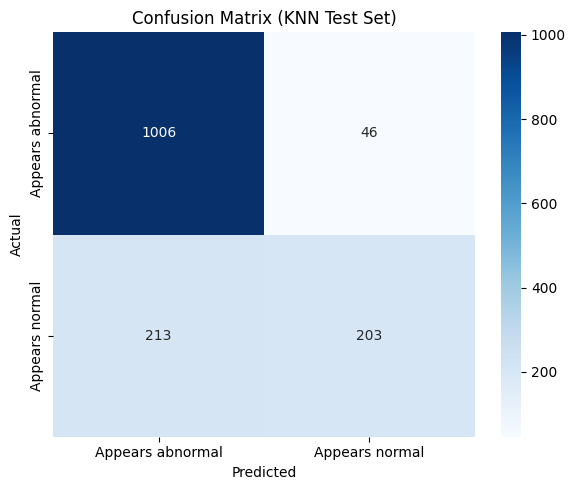

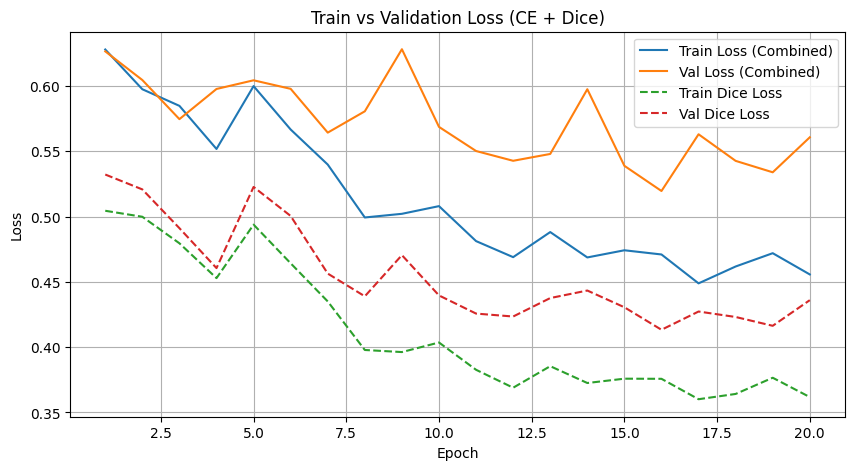

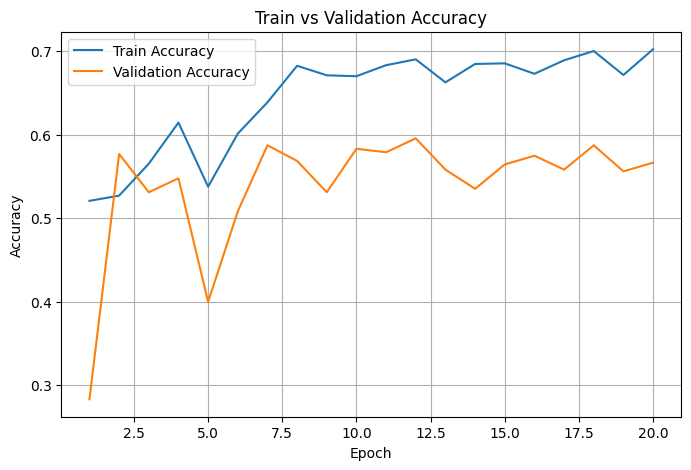


Summary:
Best AlexNet Val Accuracy: 0.5958
KNN Val Accuracy: 0.7250
Final KNN Test Accuracy: 0.8236
Final Test Precision: 0.8224, Recall: 0.8236, F1: 0.8079


In [12]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, WeightedRandomSampler, random_split
from torchvision import datasets, transforms
from tqdm import tqdm
import numpy as np
import os
import matplotlib.pyplot as plt

from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)
from sklearn.neighbors import KNeighborsClassifier
import seaborn as sns


# Device configuration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


# Paths to train and test datasets
train_dir = '/kaggle/working/PCOSGen-train/train'
test_dir = '/kaggle/working/PCOSGen-train/test'


# Image transformations
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(20),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])


# Datasets
train_dataset = datasets.ImageFolder(train_dir, transform=train_transform)
test_dataset = datasets.ImageFolder(test_dir, transform=test_transform)


# Split train_dataset into train_subset + val_subset (85/15)
val_size = int(0.15 * len(train_dataset))
train_size = len(train_dataset) - val_size
train_subset, val_subset = random_split(
    train_dataset, [train_size, val_size]
)


# Count the number of samples per class (within train_subset)
train_targets = [train_dataset.targets[i] for i in train_subset.indices]
class_counts = np.bincount(train_targets)
class_weights = 1. / class_counts
sample_weights = [class_weights[label] for label in train_targets]

sampler = WeightedRandomSampler(
    weights=sample_weights,
    num_samples=len(train_subset),
    replacement=True
)

train_loader = DataLoader(
    train_subset,
    batch_size=64,
    sampler=sampler
)

val_loader = DataLoader(
    val_subset,
    batch_size=64,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)

num_classes = len(train_dataset.classes)


# ============================================================
# AlexNet architecture (224x224 input)
# ============================================================
class AlexNet(nn.Module):
    def __init__(self, num_classes):
        super(AlexNet, self).__init__()

        self.conv1 = nn.Conv2d(3, 96, kernel_size=11, stride=4)
        self.conv2 = nn.Conv2d(96, 256, kernel_size=5, padding=2)
        self.conv3 = nn.Conv2d(256, 384, kernel_size=3, padding=1)
        self.conv4 = nn.Conv2d(384, 384, kernel_size=3, padding=1)
        self.conv5 = nn.Conv2d(384, 256, kernel_size=3, padding=1)

        self.maxpool = nn.MaxPool2d(kernel_size=3, stride=2)
        self.dropout = nn.Dropout(0.5)

        self._to_linear = None
        self.convs(torch.randn(1, 3, 224, 224))

        self.fc1 = nn.Linear(self._to_linear, 4096)
        self.fc2 = nn.Linear(4096, 4096)
        self.fc3 = nn.Linear(4096, num_classes)

    def convs(self, x):
        x = F.relu(self.conv1(x))
        x = self.maxpool(x)

        x = F.relu(self.conv2(x))
        x = self.maxpool(x)

        x = F.relu(self.conv3(x))
        x = F.relu(self.conv4(x))
        x = F.relu(self.conv5(x))

        x = self.maxpool(x)

        if self._to_linear is None:
            self._to_linear = x.view(x.size(0), -1).shape[1]

        return x

    def forward(self, x):
        x = self.convs(x)
        x = x.view(x.size(0), -1)

        x = F.relu(self.fc1(x))
        x = self.dropout(x)

        x = F.relu(self.fc2(x))
        x = self.dropout(x)

        x = self.fc3(x)

        return x

    # Extract features for KNN
    def extract_features(self, x):
        x = self.convs(x)
        x = x.view(x.size(0), -1)

        x = F.relu(self.fc1(x))
        x = self.dropout(x)

        x = F.relu(self.fc2(x))

        return x


alexnet = AlexNet(num_classes).to(device)


# ============================================================
# Dice Loss
# ============================================================
class DiceLoss(nn.Module):
    def __init__(self, num_classes, smooth=1e-6):
        super().__init__()
        self.num_classes = num_classes
        self.smooth = smooth

    def forward(self, logits, targets):
        probs = F.softmax(logits, dim=1)

        targets_one_hot = F.one_hot(
            targets,
            num_classes=self.num_classes
        ).float()

        intersection = (probs * targets_one_hot).sum(dim=0)

        union = (
            probs.sum(dim=0) +
            targets_one_hot.sum(dim=0)
        )

        dice_score = (
            (2. * intersection + self.smooth) /
            (union + self.smooth)
        )

        dice_loss = 1. - dice_score.mean()

        return dice_loss


# Combined CrossEntropy + Dice Loss
class CombinedLoss(nn.Module):
    def __init__(
        self,
        num_classes,
        ce_weight=0.5,
        dice_weight=0.5
    ):
        super().__init__()

        self.ce_loss = nn.CrossEntropyLoss()
        self.dice_loss = DiceLoss(num_classes)

        self.ce_weight = ce_weight
        self.dice_weight = dice_weight

    def forward(self, logits, targets):
        ce = self.ce_loss(logits, targets)
        dice = self.dice_loss(logits, targets)

        total = (
            self.ce_weight * ce +
            self.dice_weight * dice
        )

        return total, ce, dice


criterion = CombinedLoss(
    num_classes=num_classes,
    ce_weight=0.5,
    dice_weight=0.5
)

optimizer = optim.Adam(
    alexnet.parameters(),
    lr=0.001
)


# ============================================================
# Evaluation function
# ============================================================
def evaluate_model(model, loader):

    model.eval()

    correct = 0
    total = 0

    running_loss = 0.0
    running_ce = 0.0
    running_dice = 0.0

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss, ce, dice = criterion(
                outputs,
                labels
            )

            running_loss += loss.item()
            running_ce += ce.item()
            running_dice += dice.item()

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)

            correct += (
                predicted == labels
            ).sum().item()

    accuracy = correct / total

    n = len(loader)

    return (
        accuracy,
        running_loss / n,
        running_ce / n,
        running_dice / n
    )


def get_predictions(model, loader):

    model.eval()

    all_preds = []
    all_labels = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            _, predicted = torch.max(outputs, 1)

            all_preds.extend(
                predicted.cpu().numpy()
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

    return all_labels, all_preds


# ============================================================
# Early stopping setup
# ============================================================
best_accuracy = 0.0

best_model_path = "AlexNet_best.pkl"

patience = 8

epochs_no_improve = 0

max_epochs = 50


train_losses, train_accs = [], []
val_losses, val_accs = [], []

train_ce_losses, train_dice_losses = [], []
val_ce_losses, val_dice_losses = [], []


# ============================================================
# Train AlexNet feature extractor
# ============================================================
for epoch in range(max_epochs):

    alexnet.train()

    running_loss = 0.0
    running_ce = 0.0
    running_dice = 0.0

    correct_train = 0
    total_train = 0

    for images, labels in tqdm(train_loader):

        images = images.to(device)
        labels = labels.to(device)

        outputs = alexnet(images)

        loss, ce, dice = criterion(
            outputs,
            labels
        )

        optimizer.zero_grad()

        loss.backward()

        optimizer.step()

        running_loss += loss.item()
        running_ce += ce.item()
        running_dice += dice.item()

        _, predicted = torch.max(outputs, 1)

        total_train += labels.size(0)

        correct_train += (
            predicted == labels
        ).sum().item()

    train_accuracy = correct_train / total_train

    n_batches = len(train_loader)

    train_loss = running_loss / n_batches
    train_ce = running_ce / n_batches
    train_dice = running_dice / n_batches

    val_accuracy, val_loss, val_ce, val_dice = evaluate_model(
        alexnet,
        val_loader
    )

    train_losses.append(train_loss)
    train_accs.append(train_accuracy)

    val_losses.append(val_loss)
    val_accs.append(val_accuracy)

    train_ce_losses.append(train_ce)
    train_dice_losses.append(train_dice)

    val_ce_losses.append(val_ce)
    val_dice_losses.append(val_dice)

    print(
        f'Epoch [{epoch+1}/{max_epochs}] '
        f'Train Loss: {train_loss:.4f} '
        f'(CE: {train_ce:.4f}, Dice: {train_dice:.4f}), '
        f'Train Acc: {train_accuracy:.4f} | '
        f'Val Loss: {val_loss:.4f} '
        f'(CE: {val_ce:.4f}, Dice: {val_dice:.4f}), '
        f'Val Acc: {val_accuracy:.4f}'
    )

    # Early stopping logic
    if val_accuracy > best_accuracy:

        best_accuracy = val_accuracy

        epochs_no_improve = 0

        print(
            f'  -> Saving best model '
            f'(Val Accuracy: {best_accuracy:.4f})'
        )

        torch.save(
            alexnet.state_dict(),
            best_model_path
        )

    else:

        epochs_no_improve += 1

        print(
            f'  -> No improvement for '
            f'{epochs_no_improve}/{patience} epochs'
        )

    if epochs_no_improve >= patience:

        print(
            f'\nEarly stopping triggered at epoch '
            f'{epoch+1}. '
            f'Best Val Accuracy: {best_accuracy:.4f}'
        )

        break


# ============================================================
# Load best AlexNet
# ============================================================
best_alexnet_model = AlexNet(num_classes).to(device)

best_alexnet_model.load_state_dict(
    torch.load(
        best_model_path,
        map_location=device
    )
)


# ============================================================
# KNN
# ============================================================
print("\n" + "=" * 60)
print("Training KNN on AlexNet features")
print("=" * 60)


# Loader for extracting training features
feature_train_loader = DataLoader(
    train_subset,
    batch_size=64,
    shuffle=False
)


def extract_features(model, loader):

    model.eval()

    features = []
    labels_list = []

    with torch.no_grad():

        for images, labels in tqdm(loader):

            images = images.to(device)

            outputs = model.extract_features(images)

            features.append(
                outputs.cpu().numpy()
            )

            labels_list.append(
                labels.numpy()
            )

    features = np.concatenate(
        features,
        axis=0
    )

    labels_list = np.concatenate(
        labels_list,
        axis=0
    )

    return features, labels_list


# Extract AlexNet features
X_train, y_train = extract_features(
    best_alexnet_model,
    feature_train_loader
)

X_val, y_val = extract_features(
    best_alexnet_model,
    val_loader
)

X_test, y_test = extract_features(
    best_alexnet_model,
    test_loader
)


print("Training features shape:", X_train.shape)
print("Validation features shape:", X_val.shape)
print("Test features shape:", X_test.shape)


# ============================================================
# KNN classifier
# ============================================================
knn = KNeighborsClassifier(
    n_neighbors=5,
    n_jobs=-1
)


# Train KNN
knn.fit(
    X_train,
    y_train
)


# ============================================================
# KNN Validation
# ============================================================
knn_val_preds = knn.predict(X_val)

knn_val_accuracy = (
    knn_val_preds == y_val
).mean()

print(
    f"\nKNN Validation Accuracy: "
    f"{knn_val_accuracy:.4f}"
)


# ============================================================
# KNN TEST
# ============================================================
knn_test_preds = knn.predict(X_test)

test_accuracy = (
    knn_test_preds == y_test
).mean()


print(
    f'\nFinal KNN Test Accuracy: '
    f'{test_accuracy:.4f}'
)


# ============================================================
# Precision, Recall, F1
# ============================================================
precision = precision_score(
    y_test,
    knn_test_preds,
    average='weighted'
)

recall = recall_score(
    y_test,
    knn_test_preds,
    average='weighted'
)

f1 = f1_score(
    y_test,
    knn_test_preds,
    average='weighted'
)


print(
    f'\nTest Precision (weighted): {precision:.4f}'
)

print(
    f'Test Recall (weighted):    {recall:.4f}'
)

print(
    f'Test F1-score (weighted):  {f1:.4f}'
)


# ============================================================
# Per-class report
# ============================================================
class_names = train_dataset.classes

print('\nPer-class report:')

print(
    classification_report(
        y_test,
        knn_test_preds,
        target_names=class_names
    )
)


# ============================================================
# Confusion Matrix
# ============================================================
cm = confusion_matrix(
    y_test,
    knn_test_preds
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.title(
    'Confusion Matrix (KNN Test Set)'
)

plt.tight_layout()

plt.show()


# ============================================================
# Plot Train vs Val Loss
# ============================================================
epochs_range = range(
    1,
    len(train_losses) + 1
)

plt.figure(figsize=(10, 5))

plt.plot(
    epochs_range,
    train_losses,
    label='Train Loss (Combined)'
)

plt.plot(
    epochs_range,
    val_losses,
    label='Val Loss (Combined)'
)

plt.plot(
    epochs_range,
    train_dice_losses,
    '--',
    label='Train Dice Loss'
)

plt.plot(
    epochs_range,
    val_dice_losses,
    '--',
    label='Val Dice Loss'
)

plt.xlabel('Epoch')
plt.ylabel('Loss')

plt.title(
    'Train vs Validation Loss (CE + Dice)'
)

plt.legend()
plt.grid(True)

plt.show()


# ============================================================
# Plot Train vs Val Accuracy
# ============================================================
plt.figure(figsize=(8, 5))

plt.plot(
    epochs_range,
    train_accs,
    label='Train Accuracy'
)

plt.plot(
    epochs_range,
    val_accs,
    label='Validation Accuracy'
)

plt.xlabel('Epoch')
plt.ylabel('Accuracy')

plt.title(
    'Train vs Validation Accuracy'
)

plt.legend()
plt.grid(True)

plt.show()


# ============================================================
# Summary
# ============================================================
print('\nSummary:')

print(
    f'Best AlexNet Val Accuracy: '
    f'{best_accuracy:.4f}'
)

print(
    f'KNN Val Accuracy: '
    f'{knn_val_accuracy:.4f}'
)

print(
    f'Final KNN Test Accuracy: '
    f'{test_accuracy:.4f}'
)

print(
    f'Final Test Precision: '
    f'{precision:.4f}, '
    f'Recall: {recall:.4f}, '
    f'F1: {f1:.4f}'
)